# Choosing adjustment variables from chronological evidence

The protocol is an ordered record of seven research stages:

$$
\mathcal P=(S_1,S_2,S_3,S_4,S_5,S_6,S_7).
$$

Here, $\mathcal P$ is the complete protocol record; $S_1$ is variable selection; $S_2$ is causal discovery; $S_3$ is causal adjustment; $S_4$ is explanatory and predictive assessment; $S_5$ is portfolio construction; $S_6$ is backtesting; and $S_7$ is multiple-testing adjustment.

,Order,Stage,Record
0,1,Variable Selection,Variable Selection
1,2,Causal Discovery,Causal Discovery
2,3,Causal Adjustment Set,Causal Adjustment Set
3,4,Causal Explanatory and Predictive Power,Causal Explanatory And Predictive Power
4,5,Causal Portfolio Construction,Causal Portfolio Construction
5,6,Backtest,Backtest
6,7,Multiple Testing Adjustments,Multiple Testing Adjustments


,Item,Value
0,Source record,PROTOCOL-01
1,Source location,"PDF pages 18-22 (journal pages 27-31), Exhibit 10"
2,Trial family,declared-family
3,Declared trials,3
4,Public return observations,1760
5,Public return columns,49


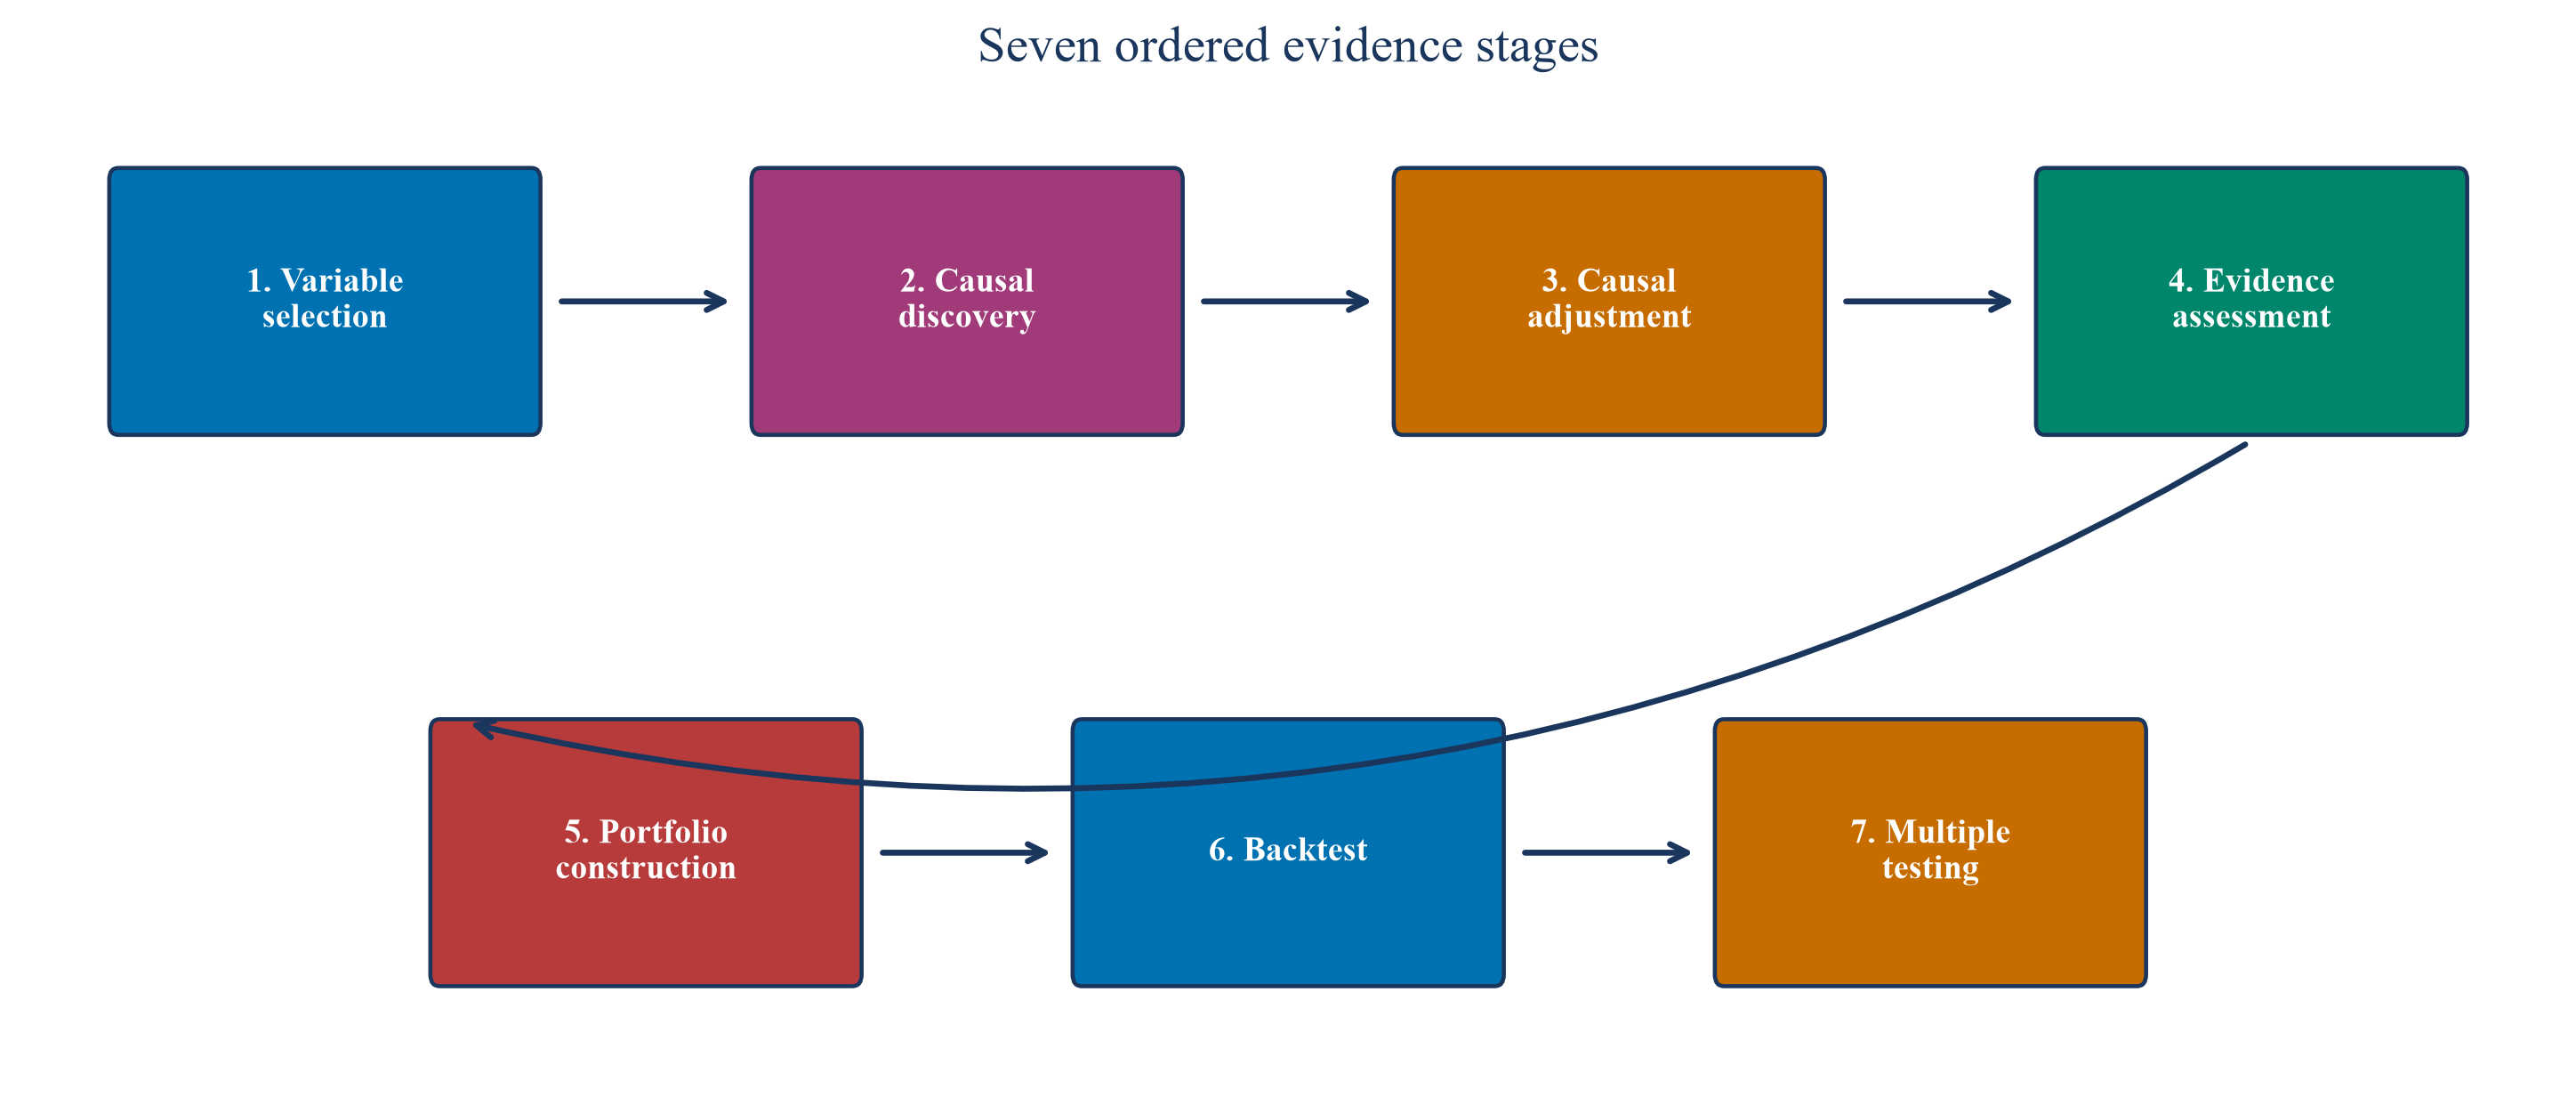

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError, fields, replace
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from scipy.stats import norm, t as student_t
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.causal_factor_analysis.protocol import BacktestStage, CausalAdjustmentSetStage, CausalDiscoveryStage, CausalExplanatoryAndPredictivePowerStage, CausalFactorProtocolReport, CausalPortfolioConstructionStage, EventHorizon, FoldEvidence, MultipleTestingAdjustmentsStage, ValidationEvidence, VariableSelectionStage, validate_causal_factor_protocol

FIGURES = ROOT / "outputs" / "figures" / "10_causal_factor_protocol"
TABLES = ROOT / "outputs" / "tables" / "10_causal_factor_protocol"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def human_label(value):
    special = {"PC": "PC", "LINGAM": "LiNGAM", "R_SQUARED": "R squared", "MEAN_SQUARED_ERROR": "Mean squared error", "BENJAMINI_HOCHBERG": "Benjamini-Hochberg", "DEFLATED_SHARPE_RATIO": "Deflated Sharpe ratio"}
    return special.get(value, value.replace("_", " ").title())

def contract_case(name, stage, action):
    try:
        action()
        return {"Case": name, "Stage": stage, "Result": "Accepted", "Message": "Record satisfies the released checks", "Rejected": False}
    except Exception as error:
        message = str(error).replace("Causal factor protocol is invalid. ", "")
        message = message.split(". ", 1)[0].rstrip(".")
        return {"Case": name, "Stage": stage, "Result": "Rejected", "Message": message, "Rejected": True}

public_dates = industry_returns.index[:6]
observation_ids = tuple(f"event-{date:%Y-%m-%d}" for date in public_dates)

def make_horizons():
    intervals = ((0.0, 2.0), (1.0, 3.0), (4.0, 5.0), (6.0, 7.0), (8.0, 9.0), (10.0, 11.0))
    return tuple(EventHorizon(observation_id, start, end) for observation_id, (start, end) in zip(observation_ids, intervals))

def make_fold(fold_id, path_id, train_positions, test_positions, refit_id):
    train_ids = tuple(observation_ids[index] for index in train_positions)
    test_ids = tuple(observation_ids[index] for index in test_positions)
    return FoldEvidence(fold_id=fold_id, path_id=path_id, train_ids=train_ids, test_ids=test_ids, fit_ids=train_ids, prediction_ids=test_ids, refit_id=refit_id, refit_components=("VARIABLE_SELECTION", "CAUSAL_ESTIMATION", "PORTFOLIO_CONSTRUCTION"))

def temporal_validation(method_labels=("PURGED_CROSS_VALIDATION",), embargo=1.0):
    return ValidationEvidence(method_labels=method_labels, event_horizons=make_horizons(), folds=(make_fold("f1", "p1", (2, 3, 4, 5), (0, 1), "r1"), make_fold("f2", "p1", (0, 1, 4, 5), (2, 3), "r2"), make_fold("f3", "p1", (0, 1, 2, 3), (4, 5), "r3")), embargo=embargo)

def cpcv_validation():
    return ValidationEvidence(method_labels=("COMBINATORIAL_PURGED_CROSS_VALIDATION",), event_horizons=make_horizons(), folds=(make_fold("p1-f1", "p1", (2, 3, 4, 5), (0, 1), "p1-r1"), make_fold("p1-f2", "p1", (0, 1, 4, 5), (2, 3), "p1-r2"), make_fold("p1-f3", "p1", (0, 1, 2, 3), (4, 5), "p1-r3"), make_fold("p2-f1", "p2", (3, 4, 5), (0, 2), "p2-r1"), make_fold("p2-f2", "p2", (2, 3, 5), (1, 4), "p2-r2"), make_fold("p2-f3", "p2", (0, 1, 2), (3, 5), "p2-r3")), embargo=1.0)

def valid_protocol_report():
    trial_ids = ("strategy-a", "strategy-b", "strategy-c")
    family_id = "declared-family"
    selection_validation = temporal_validation()
    evaluation_validation = temporal_validation()
    return CausalFactorProtocolReport(trial_family_id=family_id, declared_trial_ids=trial_ids, variable_selection=VariableSelectionStage(purpose="RISK_PREMIA_HARVESTING", selected_variables=("X", "Z", "I", "M", "C", "D"), method_labels=("MUTUAL_INFORMATION", "SHAPLEY_VALUES", "MEAN_DECREASE_IMPURITY", "PERMUTATION_FEATURE_IMPORTANCE"), overlapping_returns=True, strong_time_dependence=True, validation=selection_validation), causal_discovery=CausalDiscoveryStage(method_labels=("PC", "ECONOMIC_REASONING", "DOMAIN_EXPERTISE", "OBSERVED_OUTCOMES"), graph_id="resolved-dag", graph_nodes=("X", "Y", "Z", "I", "M", "C", "D"), directed_edges=(("Z", "X"), ("Z", "Y"), ("I", "X"), ("X", "M"), ("M", "Y"), ("X", "Y"), ("X", "C"), ("Y", "C"), ("X", "D")), graph_kind="DAG", ambiguous_edges=(), assumptions=("The recorded variables are sufficient for the target effect.", "Directions use time order and economic restrictions.")), causal_adjustment_set=CausalAdjustmentSetStage(treatment="X", outcome="Y", method_label="BACKDOOR_ADJUSTMENT", identified=True, admissible_adjustment_sets=(("Z",),), selected_adjustment_set=("Z",), confounders=("Z",), descendants=("M", "C", "D"), mediators=("M",), colliders=("C",), instruments=("I",), control_justifications=(("Z", "Common cause of factor and return."),), open_backdoor_paths=()), causal_explanatory_and_predictive_power=CausalExplanatoryAndPredictivePowerStage(task_types=("RETURN_SIZE",), estimator_label="fold-refit causal regression", explanatory_metric_labels=("R_SQUARED",), predictive_metric_labels=("MEAN_SQUARED_ERROR", "SPEARMAN_CORRELATION"), explanatory_evidence_id="explanatory-evidence", predictive_evidence_id="predictive-evidence", naive_benchmark_id="training-mean-benchmark", validation=evaluation_validation), causal_portfolio_construction=CausalPortfolioConstructionStage(method_labels=("POSITION_SIZING", "EXPOSURE_CONTROL", "ECONOMIC_RATIONALE", "FRAGILITY_STRESS_TEST", "TRANSACTION_COST_OPTIMIZATION", "TRANSFER_COEFFICIENT"), causal_exposures=("X",), controlled_unintended_exposures=("C", "D"), cost_model_id="cost-record", constraint_set_id="constraint-record", economic_rationale="Positions target the supplied X to Y effect.", fragility_scenarios=("weaken X to Y", "perturb Z to X"), transfer_coefficient=0.82), backtest=BacktestStage(method_labels=("COMBINATORIAL_PURGED_CROSS_VALIDATION",), trial_family_id=family_id, declared_trial_ids=trial_ids, validation=cpcv_validation()), multiple_testing_adjustments=MultipleTestingAdjustmentsStage(method_labels=("HOLM", "DEFLATED_SHARPE_RATIO"), trial_family_id=family_id, declared_trial_ids=trial_ids, family_partitions=(("primary", ("strategy-a", "strategy-b")), ("robustness", ("strategy-c",))), alpha=0.05, backtests_independent=False, p_value_estimator="estimator accounting for time dependence", time_dependence_model="purged temporal folds", p_value_inputs_assume_independence=False, sharpe_variance=0.04, effective_trials=2.0, sample_length=252, skewness=0.1, kurtosis=3.2, selection_bias_evidence_id="selection-bias-evidence"))

def public_trial_returns():
    base = industry_returns.iloc[:, :12].mean(axis=1).rename("Market basket")
    direction = np.sign(base.shift(1)).replace(0.0, 1.0)
    trials = pd.DataFrame({"Strategy A": base, "Strategy B": direction * base, "Strategy C": -direction * base})
    return trials.loc["2023-01-01":"2025-12-31"].dropna()

def draw_causal_graph(edges, stem, title):
    positions = {"I": (-1.7, 0.7), "Z": (-1.7, -0.7), "X": (-0.5, 0.0), "M": (0.5, 0.8), "Y": (1.6, 0.0), "C": (0.5, -0.8), "D": (-0.4, -1.25)}
    colors = {"I": palette["violet"], "Z": palette["amber"], "X": palette["cyan"], "M": palette["green"], "Y": palette["rose"], "C": palette["muted"], "D": palette["text"]}
    figure, axis = plt.subplots(figsize=(9.0, 5.2))
    for source_node, target_node in edges:
        start = positions[source_node]
        end = positions[target_node]
        axis.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "color": palette["grid"], "lw": 1.8, "shrinkA": 18, "shrinkB": 18})
    for node, (x_value, y_value) in positions.items():
        axis.scatter([x_value], [y_value], s=900, color=colors[node], edgecolor=palette["text"], linewidth=1.2, zorder=3)
        axis.text(x_value, y_value, node, ha="center", va="center", color=palette["background"], fontsize=12, fontweight="bold", zorder=4)
    axis.set_xlim(-2.2, 2.1)
    axis.set_ylim(-1.65, 1.3)
    axis.set_title(title)
    axis.axis("off")
    save_figure(figure, stem)

report = validate_causal_factor_protocol(valid_protocol_report())
stage_table = pd.DataFrame([{"Order": index, "Stage": name, "Record": type(stage).__name__.replace("Stage", "").replace("CausalFactorProtocolReport", "Complete report")} for index, (name, stage) in enumerate(report.stages, 1)])
stage_table["Record"] = stage_table["Record"].map(lambda value: re.sub(r"(?<!^)(?=[A-Z])", " ", value).strip())
save_table(stage_table, "protocol_stage_order", "The seven protocol stages in their required order.", "tab:chapter28-stage-order")
display(stage_table)

provenance_table = pd.DataFrame([{"Item": "Source record", "Value": report.source_oracle}, {"Item": "Source location", "Value": report.source_locator}, {"Item": "Trial family", "Value": report.trial_family_id}, {"Item": "Declared trials", "Value": len(report.declared_trial_ids)}, {"Item": "Public return observations", "Value": len(industry_returns)}, {"Item": "Public return columns", "Value": industry_returns.shape[1]}])
save_table(provenance_table, "protocol_provenance", "Source, family, and public-data facts used by the notebooks.", "tab:chapter28-provenance")
display(provenance_table)

figure, axis = plt.subplots(figsize=(12.2, 4.8))
stage_colors = [palette["cyan"], palette["violet"], palette["amber"], palette["green"], palette["rose"], palette["cyan"], palette["amber"]]
stage_positions = [(0.9, 3.0), (3.7, 3.0), (6.5, 3.0), (9.3, 3.0), (2.3, 1.1), (5.1, 1.1), (7.9, 1.1)]
short_names = ["Variable\nselection", "Causal\ndiscovery", "Causal\nadjustment", "Evidence\nassessment", "Portfolio\nconstruction", "Backtest", "Multiple\ntesting"]
for index, ((x_value, y_value), name, color) in enumerate(zip(stage_positions, short_names, stage_colors)):
    box = FancyBboxPatch((x_value - 0.9, y_value - 0.42), 1.8, 0.84, boxstyle="round,pad=0.04", facecolor=color, edgecolor=palette["text"], linewidth=1.1)
    axis.add_patch(box)
    axis.text(x_value, y_value, f"{index + 1}. {name}", ha="center", va="center", color=palette["background"], fontsize=9.2, fontweight="bold")
    if index < 3:
        axis.annotate("", xy=(stage_positions[index + 1][0] - 1.0, stage_positions[index + 1][1]), xytext=(x_value + 1.0, y_value), arrowprops={"arrowstyle": "->", "color": palette["text"], "lw": 1.6})
    elif index == 3:
        axis.annotate("", xy=(stage_positions[4][0] - 0.8, stage_positions[4][1] + 0.45), xytext=(x_value, y_value - 0.48), arrowprops={"arrowstyle": "->", "color": palette["text"], "lw": 1.6, "connectionstyle": "arc3,rad=-0.2"})
    elif index < 6:
        axis.annotate("", xy=(stage_positions[index + 1][0] - 1.0, stage_positions[index + 1][1]), xytext=(x_value + 1.0, y_value), arrowprops={"arrowstyle": "->", "color": palette["text"], "lw": 1.6})
axis.set_xlim(-0.4, 10.6)
axis.set_ylim(0.35, 3.75)
axis.set_title("Seven ordered evidence stages")
axis.axis("off")
save_figure(figure, "protocol_stage_flow")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Aligning outcome horizons with fold boundaries

Two return horizons overlap when their half-open intervals share time:

$$
O_{ij}=\mathbf 1\!\left\{\max(s_i,s_j)<\min(e_i,e_j)\right\}.
$$

Here, $O_{ij}$ is one when events $i$ and $j$ overlap and zero otherwise; $s_i$ and $e_i$ are the start and end coordinates of event $i$; $s_j$ and $e_j$ are the corresponding coordinates for event $j$; and $\mathbf 1\{\cdot\}$ is the indicator function.

,Event,Public date label,Start coordinate,End coordinate,Length
0,1,2019-01-02,0,2,2
1,2,2019-01-03,1,3,2
2,3,2019-01-04,4,5,1
3,4,2019-01-07,6,7,1
4,5,2019-01-08,8,9,1
5,6,2019-01-09,10,11,1


,Event,Event 1,Event 2,Event 3,Event 4,Event 5,Event 6
0,Event 1,1,1,0,0,0,0
1,Event 2,1,1,0,0,0,0
2,Event 3,0,0,1,0,0,0
3,Event 4,0,0,0,1,0,0
4,Event 5,0,0,0,0,1,0
5,Event 6,0,0,0,0,0,1


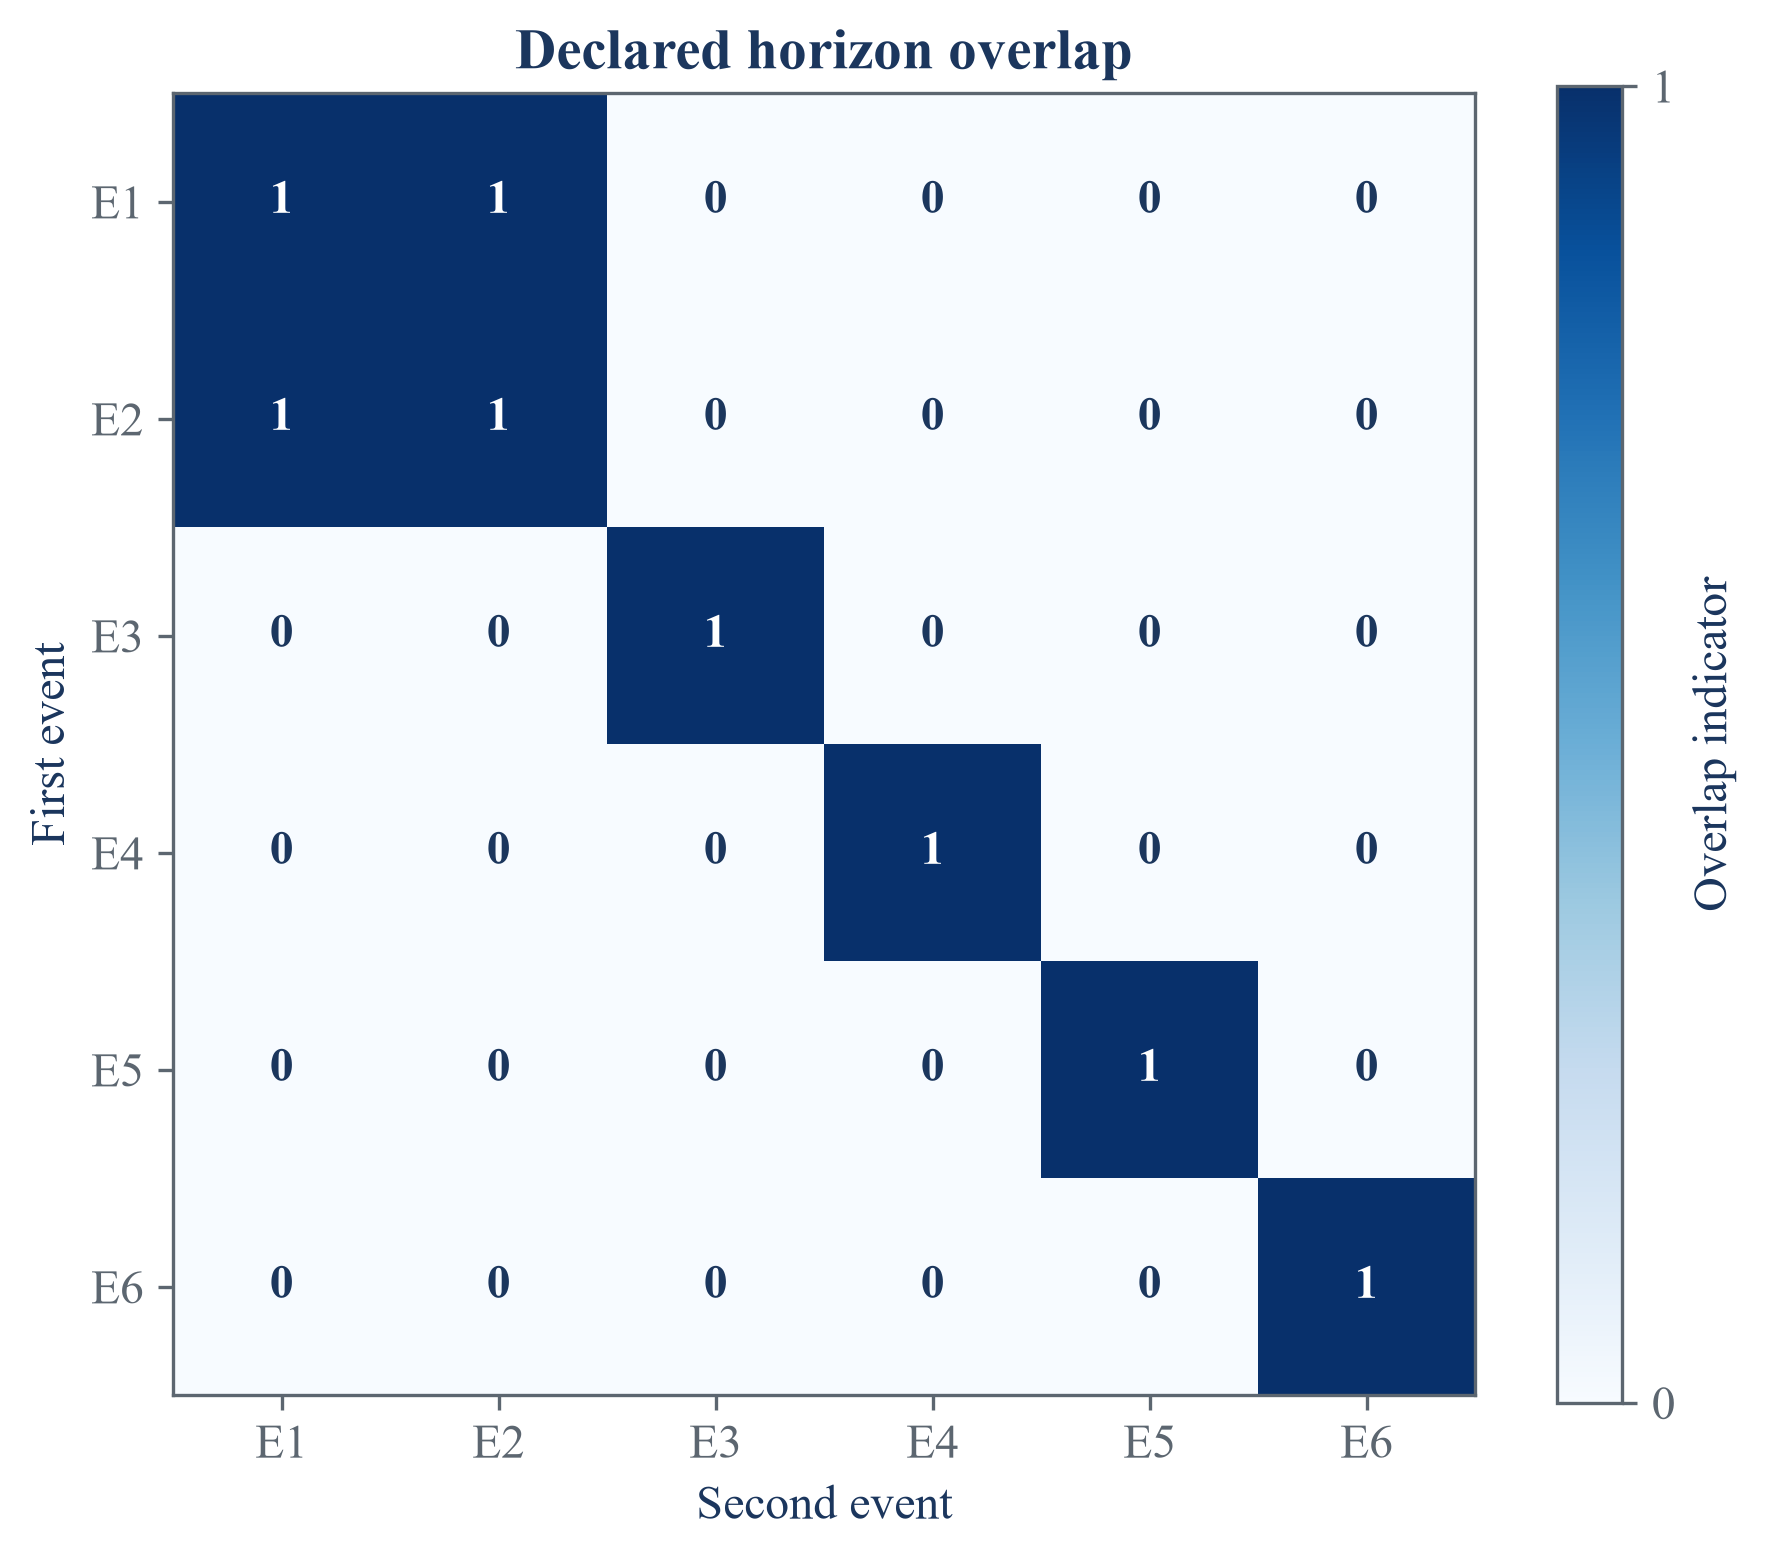

In [2]:
horizons = report.variable_selection.validation.event_horizons
horizon_table = pd.DataFrame([{"Event": index + 1, "Public date label": item.observation_id.removeprefix("event-"), "Start coordinate": item.start, "End coordinate": item.end, "Length": item.end - item.start} for index, item in enumerate(horizons)])
save_table(horizon_table, "protocol_event_horizons", "Public-date event labels and their declared return horizons.", "tab:chapter28-event-horizons")
display(horizon_table)

intervals = [(float(item.start), float(item.end)) for item in horizons]
overlap = np.array([[max(left[0], right[0]) < min(left[1], right[1]) for right in intervals] for left in intervals], dtype=int)
overlap_frame = pd.DataFrame(overlap, columns=[f"Event {index + 1}" for index in range(len(horizons))])
overlap_frame.insert(0, "Event", [f"Event {index + 1}" for index in range(len(horizons))])
save_table(overlap_frame, "protocol_overlap_matrix", "Pairwise overlap indicators for the declared return horizons.", "tab:chapter28-overlap-matrix")
display(overlap_frame)

figure, axis = plt.subplots(figsize=(7.0, 5.7))
image = axis.imshow(overlap, cmap="Blues", vmin=0, vmax=1)
for row in range(overlap.shape[0]):
    for column in range(overlap.shape[1]):
        axis.text(column, row, str(overlap[row, column]), ha="center", va="center", color=palette["text"] if overlap[row, column] == 0 else palette["background"], fontweight="bold")
axis.set_xticks(range(len(horizons)), [f"E{index + 1}" for index in range(len(horizons))])
axis.set_yticks(range(len(horizons)), [f"E{index + 1}" for index in range(len(horizons))])
axis.set_xlabel("Second event")
axis.set_ylabel("First event")
axis.set_title("Declared horizon overlap")
figure.colorbar(image, ax=axis, ticks=[0, 1], label="Overlap indicator")
save_figure(figure, "protocol_overlap_heatmap")

## Separating training observations around validation periods

The safe training set removes overlapping horizons and observations inside the post-test embargo:

$$
\mathcal T_k^{\mathrm{safe}}=\left\{i\in\mathcal T_k: [s_i,e_i)\cap[s_j,e_j)=\varnothing\ \text{and}\ s_i\notin[e_j,e_j+h)\ \text{for every }j\in\mathcal V_k\right\}.
$$

Here, $\mathcal T_k$ is the proposed training set for fold $k$; $\mathcal V_k$ is its test set; $[s_i,e_i)$ is a training horizon; $[s_j,e_j)$ is a test horizon; $h$ is the embargo length; and $\mathcal T_k^{\mathrm{safe}}$ is the retained training membership.

,Fold,Path,Training events,Test events,Refit record,Refit parts
0,F1,P1,"3, 4, 5, 6","1, 2",R1,3
1,F2,P1,"1, 2, 5, 6","3, 4",R2,3
2,F3,P1,"1, 2, 3, 4","5, 6",R3,3


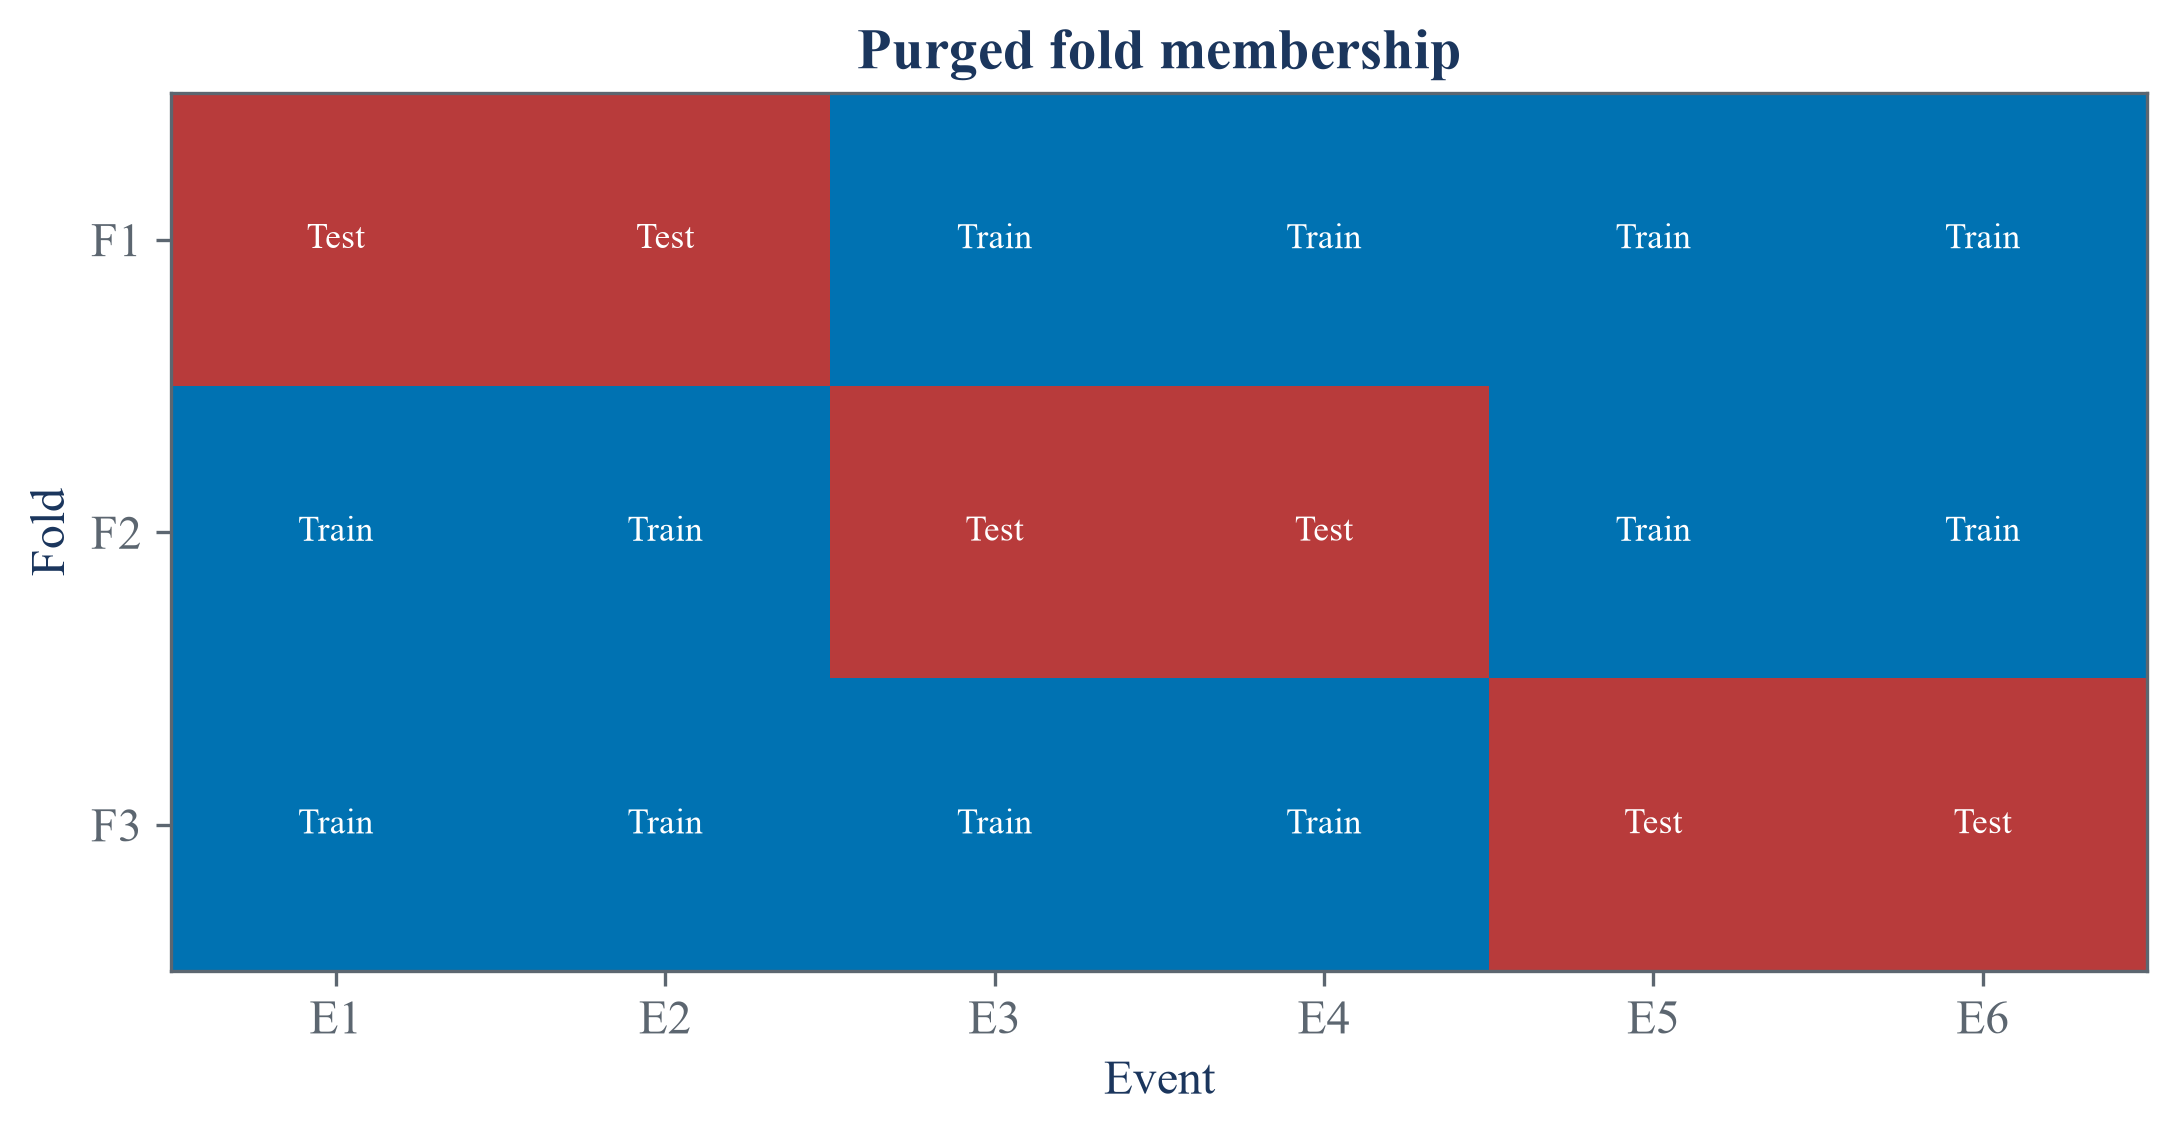

,Embargo,Result,Message,Accepted
0,0,Rejected,Stage 1: strong time dependence requires an em...,False
1,0.25,Accepted,Record satisfies the released checks,True
2,0.5,Accepted,Record satisfies the released checks,True
3,1,Accepted,Record satisfies the released checks,True
4,1.25,Rejected,Stage 1: post-test embargo observations must b...,False


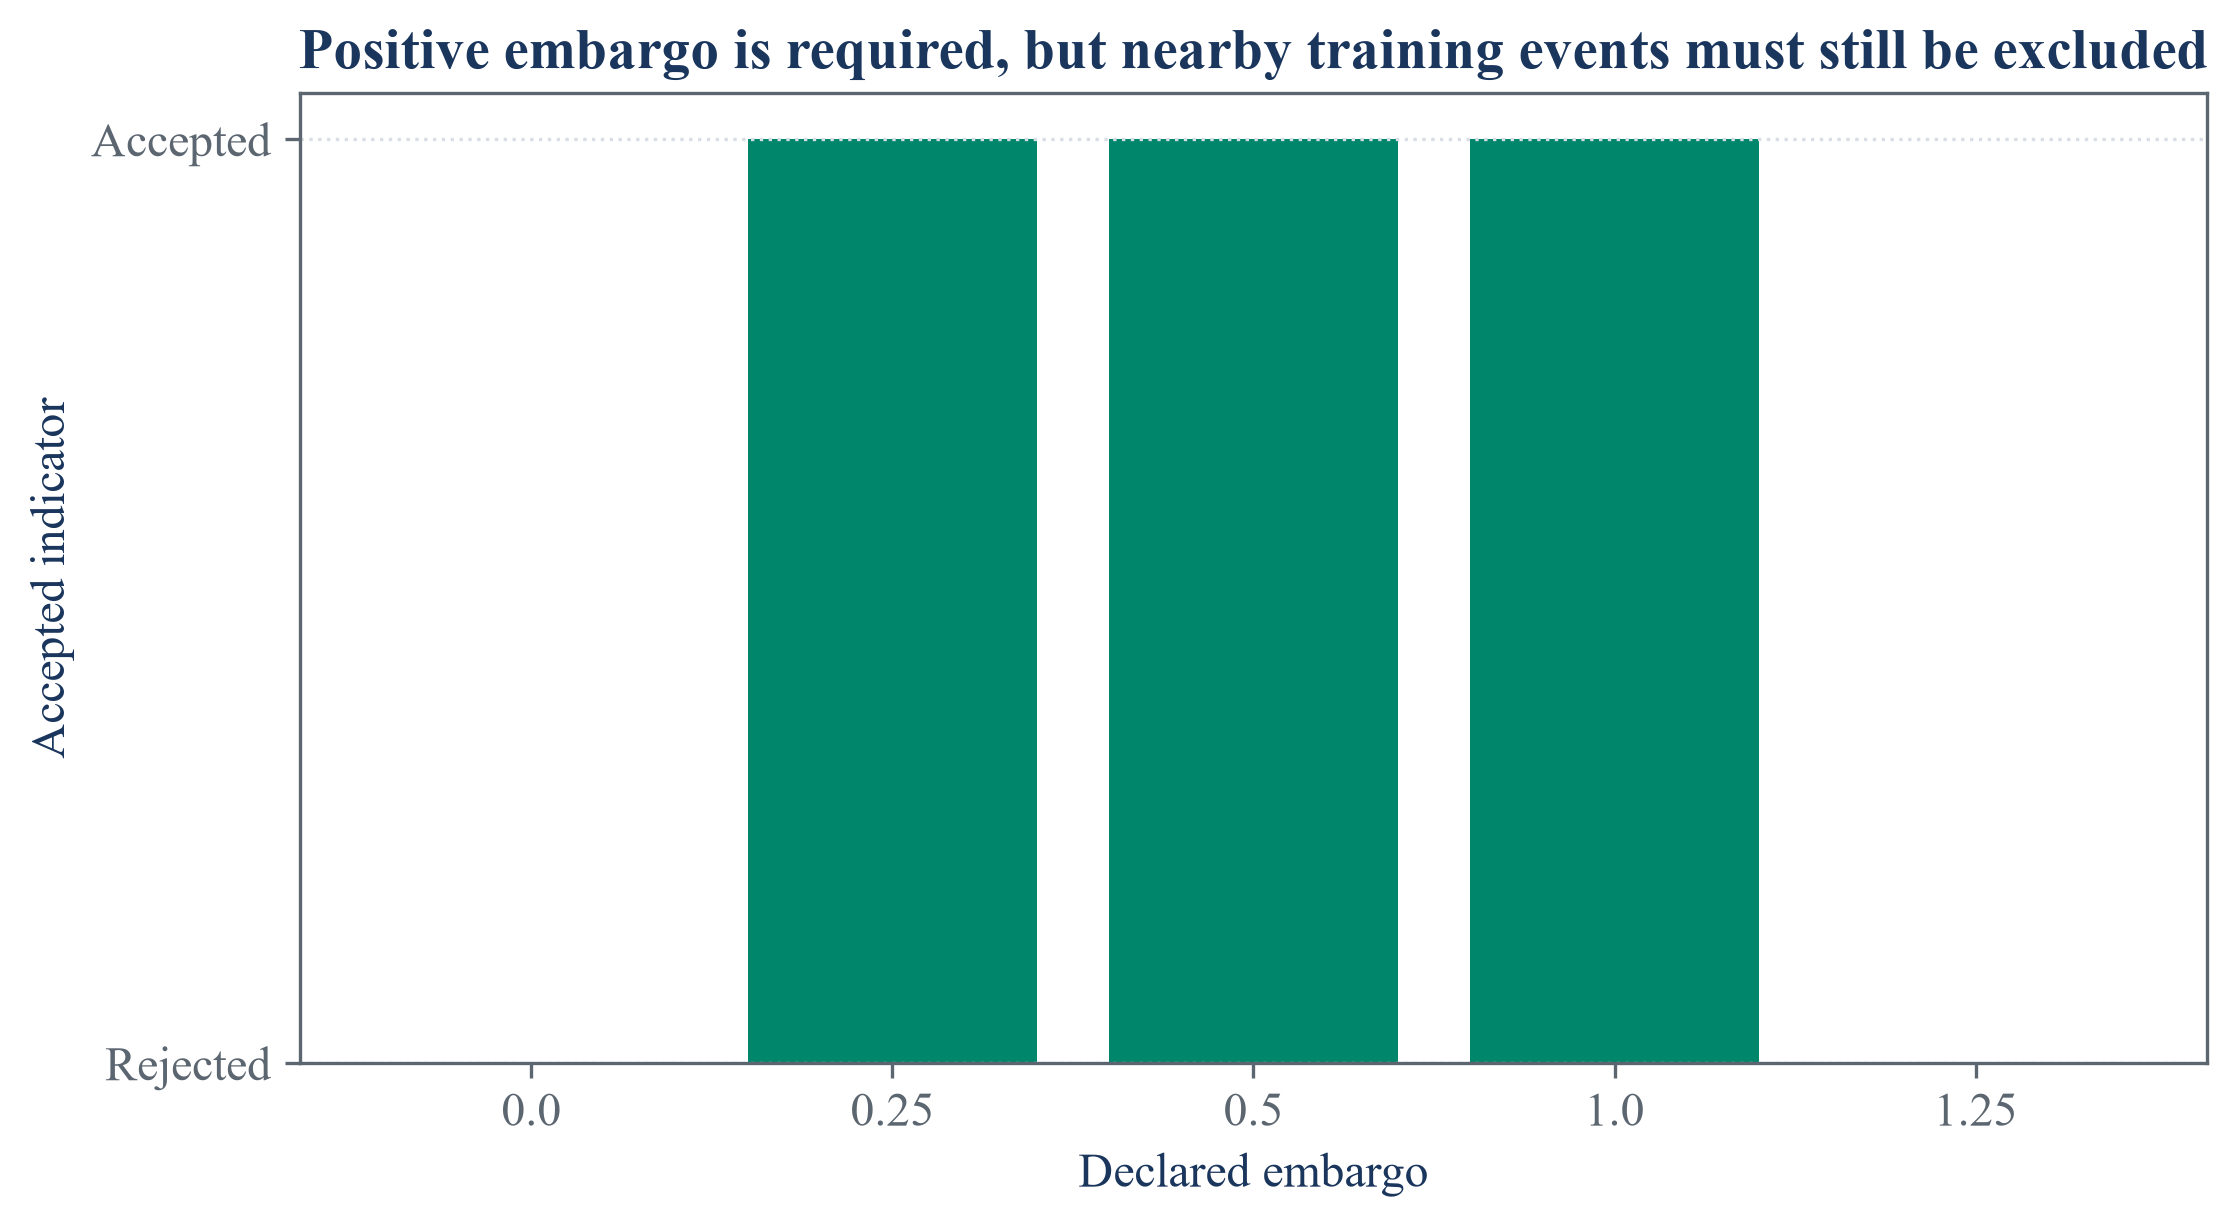

In [3]:
validation = report.variable_selection.validation
fold_rows = []
for fold in validation.folds:
    fold_rows.append({"Fold": fold.fold_id.upper(), "Path": fold.path_id.upper(), "Training events": ", ".join(str(observation_ids.index(value) + 1) for value in fold.train_ids), "Test events": ", ".join(str(observation_ids.index(value) + 1) for value in fold.test_ids), "Refit record": fold.refit_id.upper(), "Refit parts": len(fold.refit_components)})
fold_table = pd.DataFrame(fold_rows)
save_table(fold_table, "protocol_fold_membership", "Purged training and test membership for each fold.", "tab:chapter28-fold-membership")
display(fold_table)

membership = np.zeros((len(validation.folds), len(observation_ids)))
for row, fold in enumerate(validation.folds):
    for value in fold.train_ids:
        membership[row, observation_ids.index(value)] = 1
    for value in fold.test_ids:
        membership[row, observation_ids.index(value)] = -1
figure, axis = plt.subplots(figsize=(8.5, 3.8))
image = axis.imshow(membership, cmap=matplotlib.colors.ListedColormap([palette["rose"], palette["axes"], palette["cyan"]]), vmin=-1, vmax=1, aspect="auto")
for row in range(membership.shape[0]):
    for column in range(membership.shape[1]):
        label = "Test" if membership[row, column] == -1 else "Train" if membership[row, column] == 1 else ""
        axis.text(column, row, label, ha="center", va="center", fontsize=8.5, color=palette["background"] if label else palette["text"])
axis.set_xticks(range(len(observation_ids)), [f"E{index + 1}" for index in range(len(observation_ids))])
axis.set_yticks(range(len(validation.folds)), [fold.fold_id.upper() for fold in validation.folds])
axis.set_xlabel("Event")
axis.set_ylabel("Fold")
axis.set_title("Purged fold membership")
save_figure(figure, "protocol_fold_membership")

embargo_rows = []
for embargo_value in [0.0, 0.25, 0.5, 1.0, 1.25]:
    changed_validation = replace(report.variable_selection.validation, embargo=embargo_value)
    changed_selection = replace(report.variable_selection, validation=changed_validation)
    result = contract_case(f"Embargo {display_float(embargo_value)}", "Stage 1", lambda changed_selection=changed_selection: validate_causal_factor_protocol(replace(report, variable_selection=changed_selection)))
    embargo_rows.append({"Embargo": embargo_value, "Result": result["Result"], "Message": result["Message"], "Accepted": not result["Rejected"]})
embargo_table = pd.DataFrame(embargo_rows)
save_table(embargo_table, "protocol_embargo_sweep", "Acceptance across declared embargo lengths.", "tab:chapter28-embargo-sweep")
display(embargo_table)

figure, axis = plt.subplots(figsize=(8.2, 4.2))
colors = [palette["green"] if value else palette["rose"] for value in embargo_table["Accepted"]]
axis.bar(embargo_table["Embargo"].astype(str), embargo_table["Accepted"].astype(int), color=colors)
axis.set_xlabel("Declared embargo")
axis.set_ylabel("Accepted indicator")
axis.set_yticks([0, 1], ["Rejected", "Accepted"])
axis.set_title("Positive embargo is required, but nearby training events must still be excluded")
axis.grid(True, axis="y")
save_figure(figure, "protocol_embargo_sweep")

## Foldwise Variable Selection

A selection rule must be fitted again inside each training fold:

$$
\widehat{\mathcal V}_k=\mathcal A_{\mathrm{select}}(D_{\mathcal T_k}),
\qquad
D_{\mathcal T_k}\cap D_{\mathcal V_k}=\varnothing.
$$

Here, $\widehat{\mathcal V}_k$ is the variable set selected in fold $k$; $\mathcal A_{\mathrm{select}}$ is the declared selection rule; $D_{\mathcal T_k}$ contains training observations; $D_{\mathcal V_k}$ contains test observations; and the empty intersection states that fitting and testing use disjoint memberships.

,Selection method,Declared,Temporal refit required
0,Mutual Information,True,False
1,Shapley Values,True,False
2,Mean Decrease Impurity,True,False
3,Permutation Feature Importance,True,True


,Fold,Refit record,Part refitted,Required in Stage 1
0,F1,R1,Variable Selection,True
1,F1,R1,Causal Estimation,False
2,F1,R1,Portfolio Construction,False
3,F2,R2,Variable Selection,True
4,F2,R2,Causal Estimation,False
5,F2,R2,Portfolio Construction,False
6,F3,R3,Variable Selection,True
7,F3,R3,Causal Estimation,False
8,F3,R3,Portfolio Construction,False


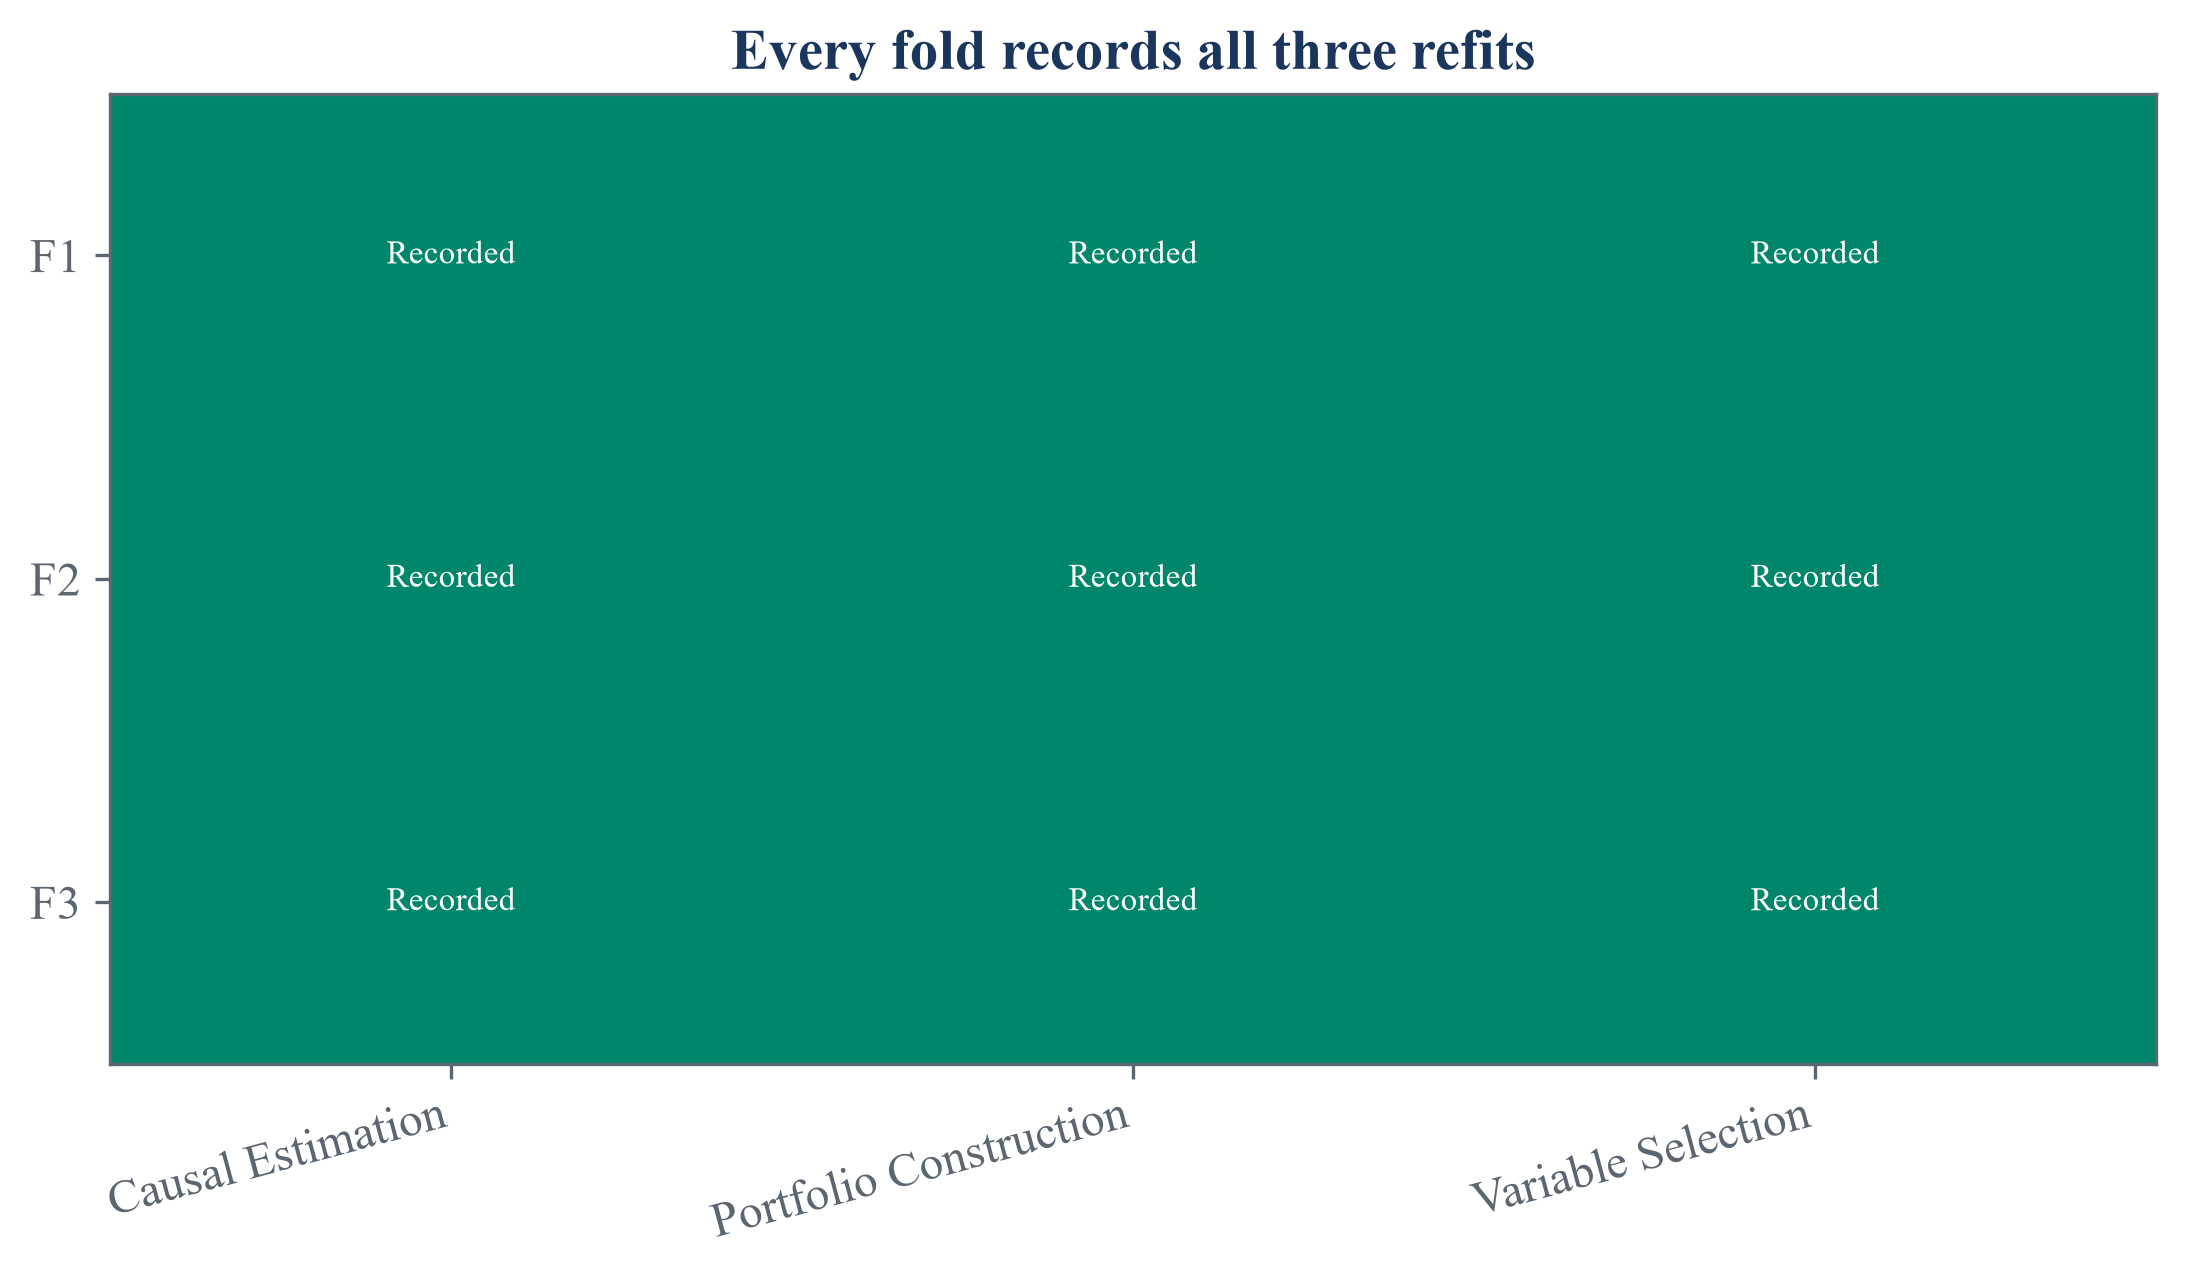

In [4]:
selection_methods = pd.DataFrame([{"Selection method": human_label(value), "Declared": True, "Temporal refit required": value == "PERMUTATION_FEATURE_IMPORTANCE"} for value in report.variable_selection.method_labels])
save_table(selection_methods, "protocol_selection_methods", "Declared variable-selection methods and temporal-refit requirement.", "tab:chapter28-selection-methods")
display(selection_methods)

refit_rows = []
for fold in report.variable_selection.validation.folds:
    for component in fold.refit_components:
        refit_rows.append({"Fold": fold.fold_id.upper(), "Refit record": fold.refit_id.upper(), "Part refitted": human_label(component), "Required in Stage 1": component == "VARIABLE_SELECTION"})
refit_table = pd.DataFrame(refit_rows)
save_table(refit_table, "protocol_selection_refits", "Recorded refits within each training fold.", "tab:chapter28-selection-refits")
display(refit_table)

refit_matrix = refit_table.pivot_table(index="Fold", columns="Part refitted", values="Required in Stage 1", aggfunc="size", fill_value=0)
figure, axis = plt.subplots(figsize=(8.8, 4.2))
axis.imshow((refit_matrix > 0).astype(int), cmap=matplotlib.colors.ListedColormap([palette["axes"], palette["green"]]), vmin=0, vmax=1, aspect="auto")
axis.set_xticks(range(refit_matrix.shape[1]), refit_matrix.columns, rotation=15, ha="right")
axis.set_yticks(range(refit_matrix.shape[0]), refit_matrix.index)
axis.set_title("Every fold records all three refits")
for row in range(refit_matrix.shape[0]):
    for column in range(refit_matrix.shape[1]):
        axis.text(column, row, "Recorded" if refit_matrix.iloc[row, column] else "Missing", ha="center", va="center", fontsize=8, color=palette["background"] if refit_matrix.iloc[row, column] else palette["text"])
save_figure(figure, "protocol_selection_refits")

## Declaring assumptions behind graph discovery

The discovery record states a directed graph and the assumptions used to orient it:

$$
\mathcal G=(\mathcal V,\mathcal E),
\qquad
\mathcal E\subseteq \mathcal V\times\mathcal V,
\qquad
\mathcal G\ \text{contains no directed cycle}.
$$

Here, $\mathcal G$ is the declared causal graph; $\mathcal V$ is its node set; $\mathcal E$ is its directed-edge set; an ordered pair in $\mathcal E$ points from a proposed cause to a proposed effect; and the final condition makes the graph acyclic.

,From,To,Directed claim
0,Z,X,Z to X
1,Z,Y,Z to Y
2,I,X,I to X
3,X,M,X to M
4,M,Y,M to Y
5,X,Y,X to Y
6,X,C,X to C
7,Y,C,Y to C
8,X,D,X to D


,Assumption,Statement
0,1,The recorded variables are sufficient for the ...
1,2,Directions use time order and economic restric...


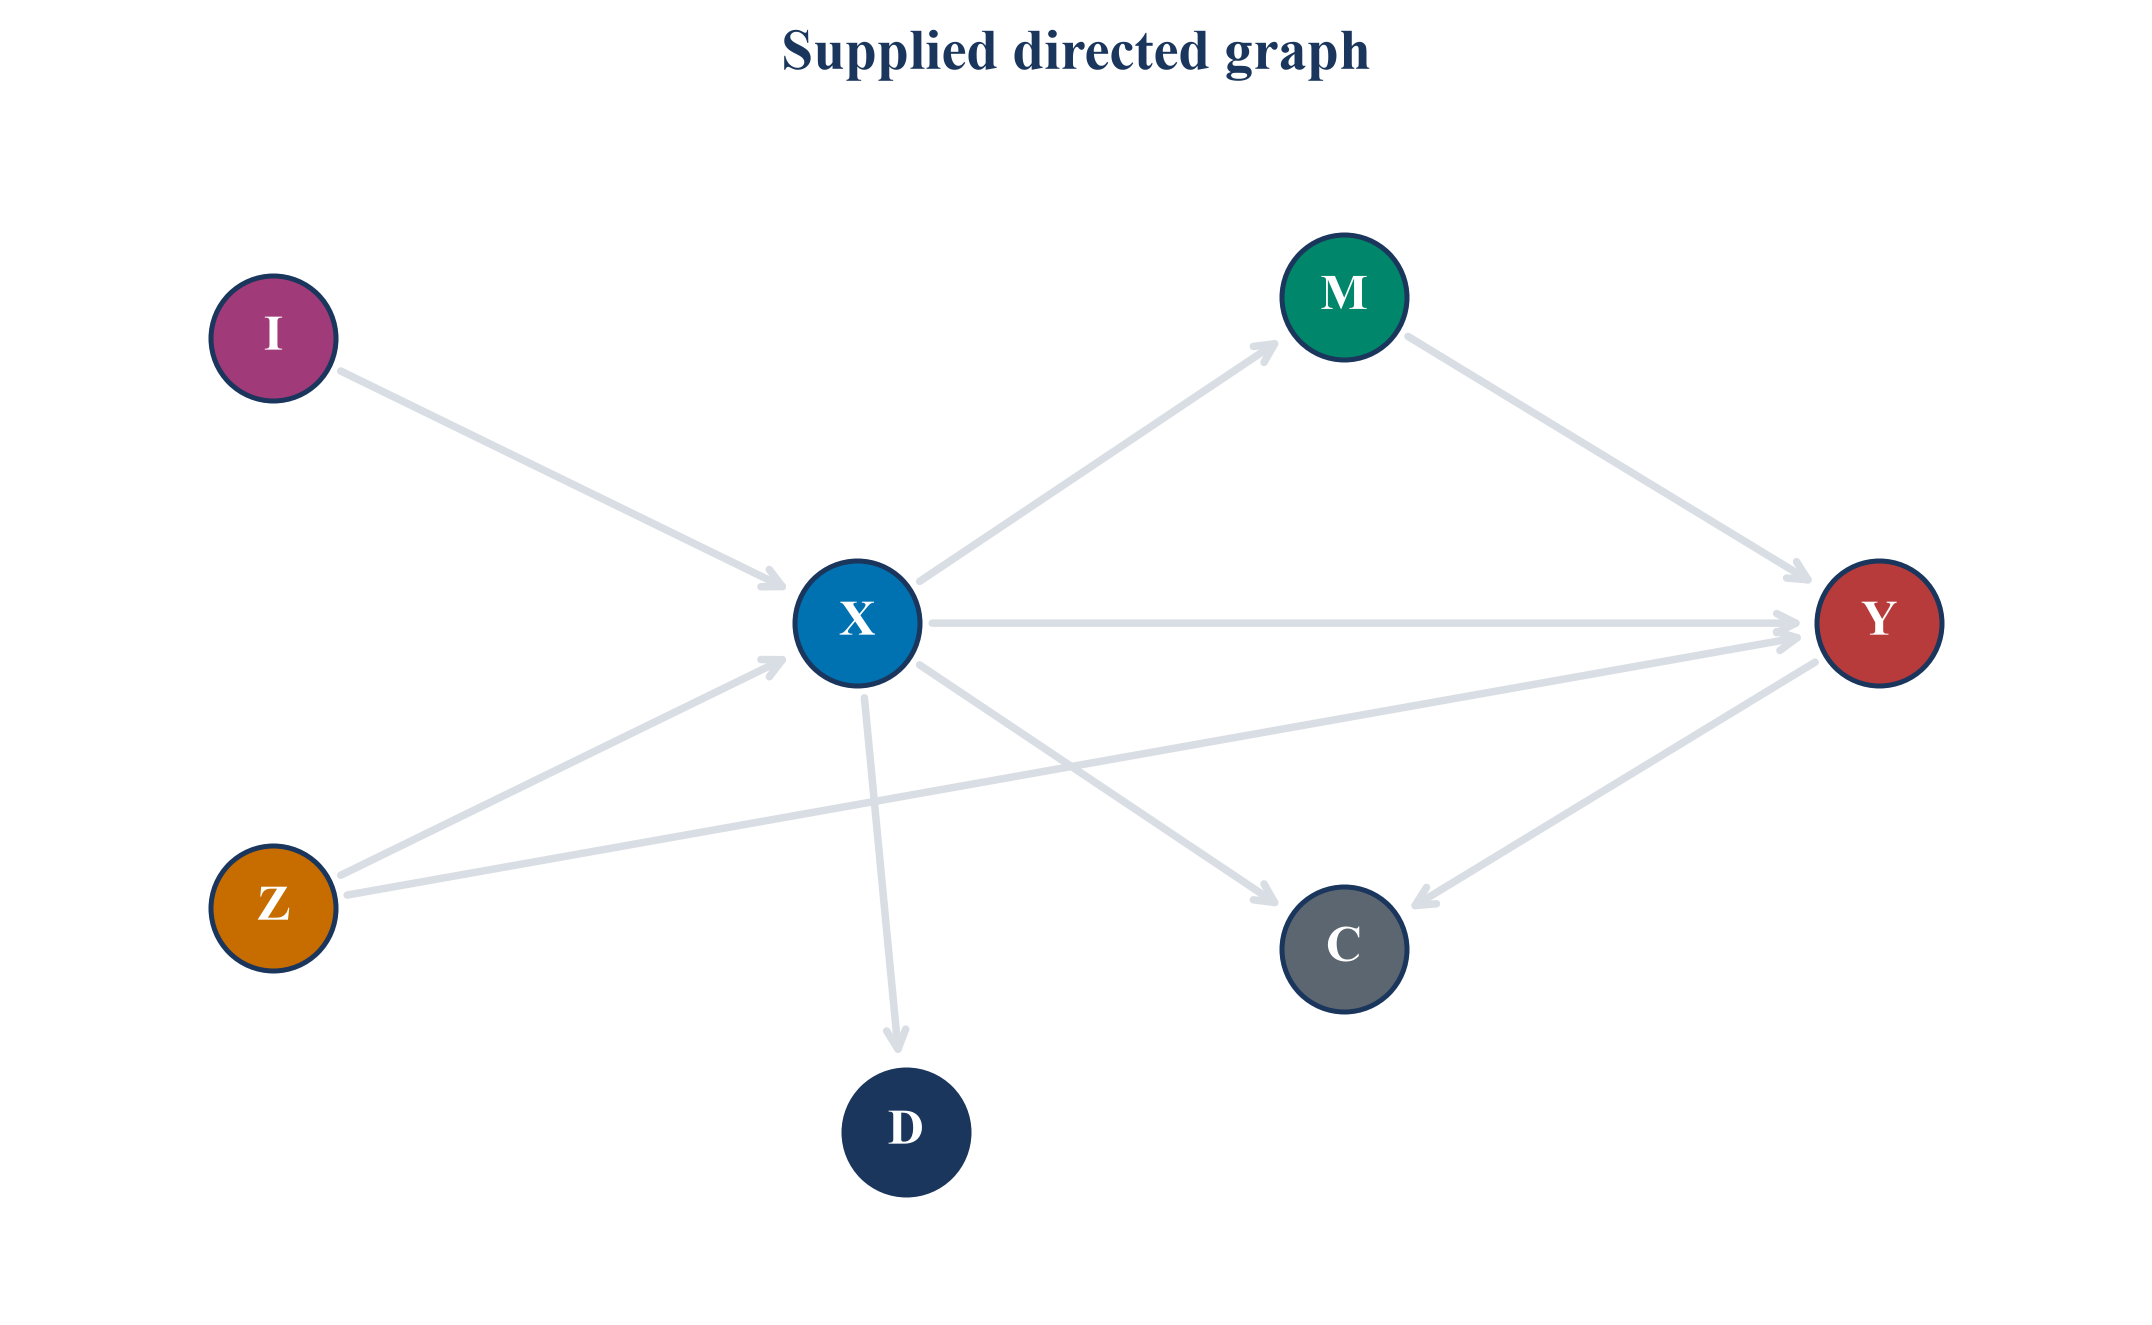

In [5]:
discovery = report.causal_discovery
graph_table = pd.DataFrame([{"From": source_node, "To": target_node, "Directed claim": f"{source_node} to {target_node}"} for source_node, target_node in discovery.directed_edges])
save_table(graph_table, "protocol_graph_edges", "Directed edges in the supplied graph.", "tab:chapter28-graph-edges")
display(graph_table)

assumption_table = pd.DataFrame([{"Assumption": index + 1, "Statement": statement} for index, statement in enumerate(discovery.assumptions)])
save_table(assumption_table, "protocol_graph_assumptions", "Assumptions attached to the supplied graph.", "tab:chapter28-graph-assumptions")
display(assumption_table)
draw_causal_graph(discovery.directed_edges, "protocol_causal_graph", "Supplied directed graph")

## Choosing adjustment roles before estimation

A valid back-door set identifies the intervention distribution through observed conditional distributions:

$$
p(y\mid\operatorname{do}(x))=\sum_z p(y\mid x,z)p(z).
$$

Here, $x$ is the treatment value; $y$ is the outcome value; $z$ ranges over a valid adjustment set; $\operatorname{do}(x)$ denotes intervention; $p(y\mid x,z)$ is the observed conditional outcome distribution; and $p(z)$ is the observed distribution of the adjustment variables.

,Variable,Graph role,Used as ordinary control
0,X,Treatment,False
1,Y,Outcome,False
2,Z,Confounder,True
3,M,Mediator,False
4,C,Collider,False
5,M,Descendant,False
6,C,Descendant,False
7,D,Descendant,False
8,I,Instrument,False
9,Z,Selected control,True


,Item,Value
0,Identification method,Backdoor Adjustment
1,Identified,Yes
2,Admissible sets,Z
3,Selected set,Z
4,Open back-door paths,0
5,Control reason,Common cause of factor and return.


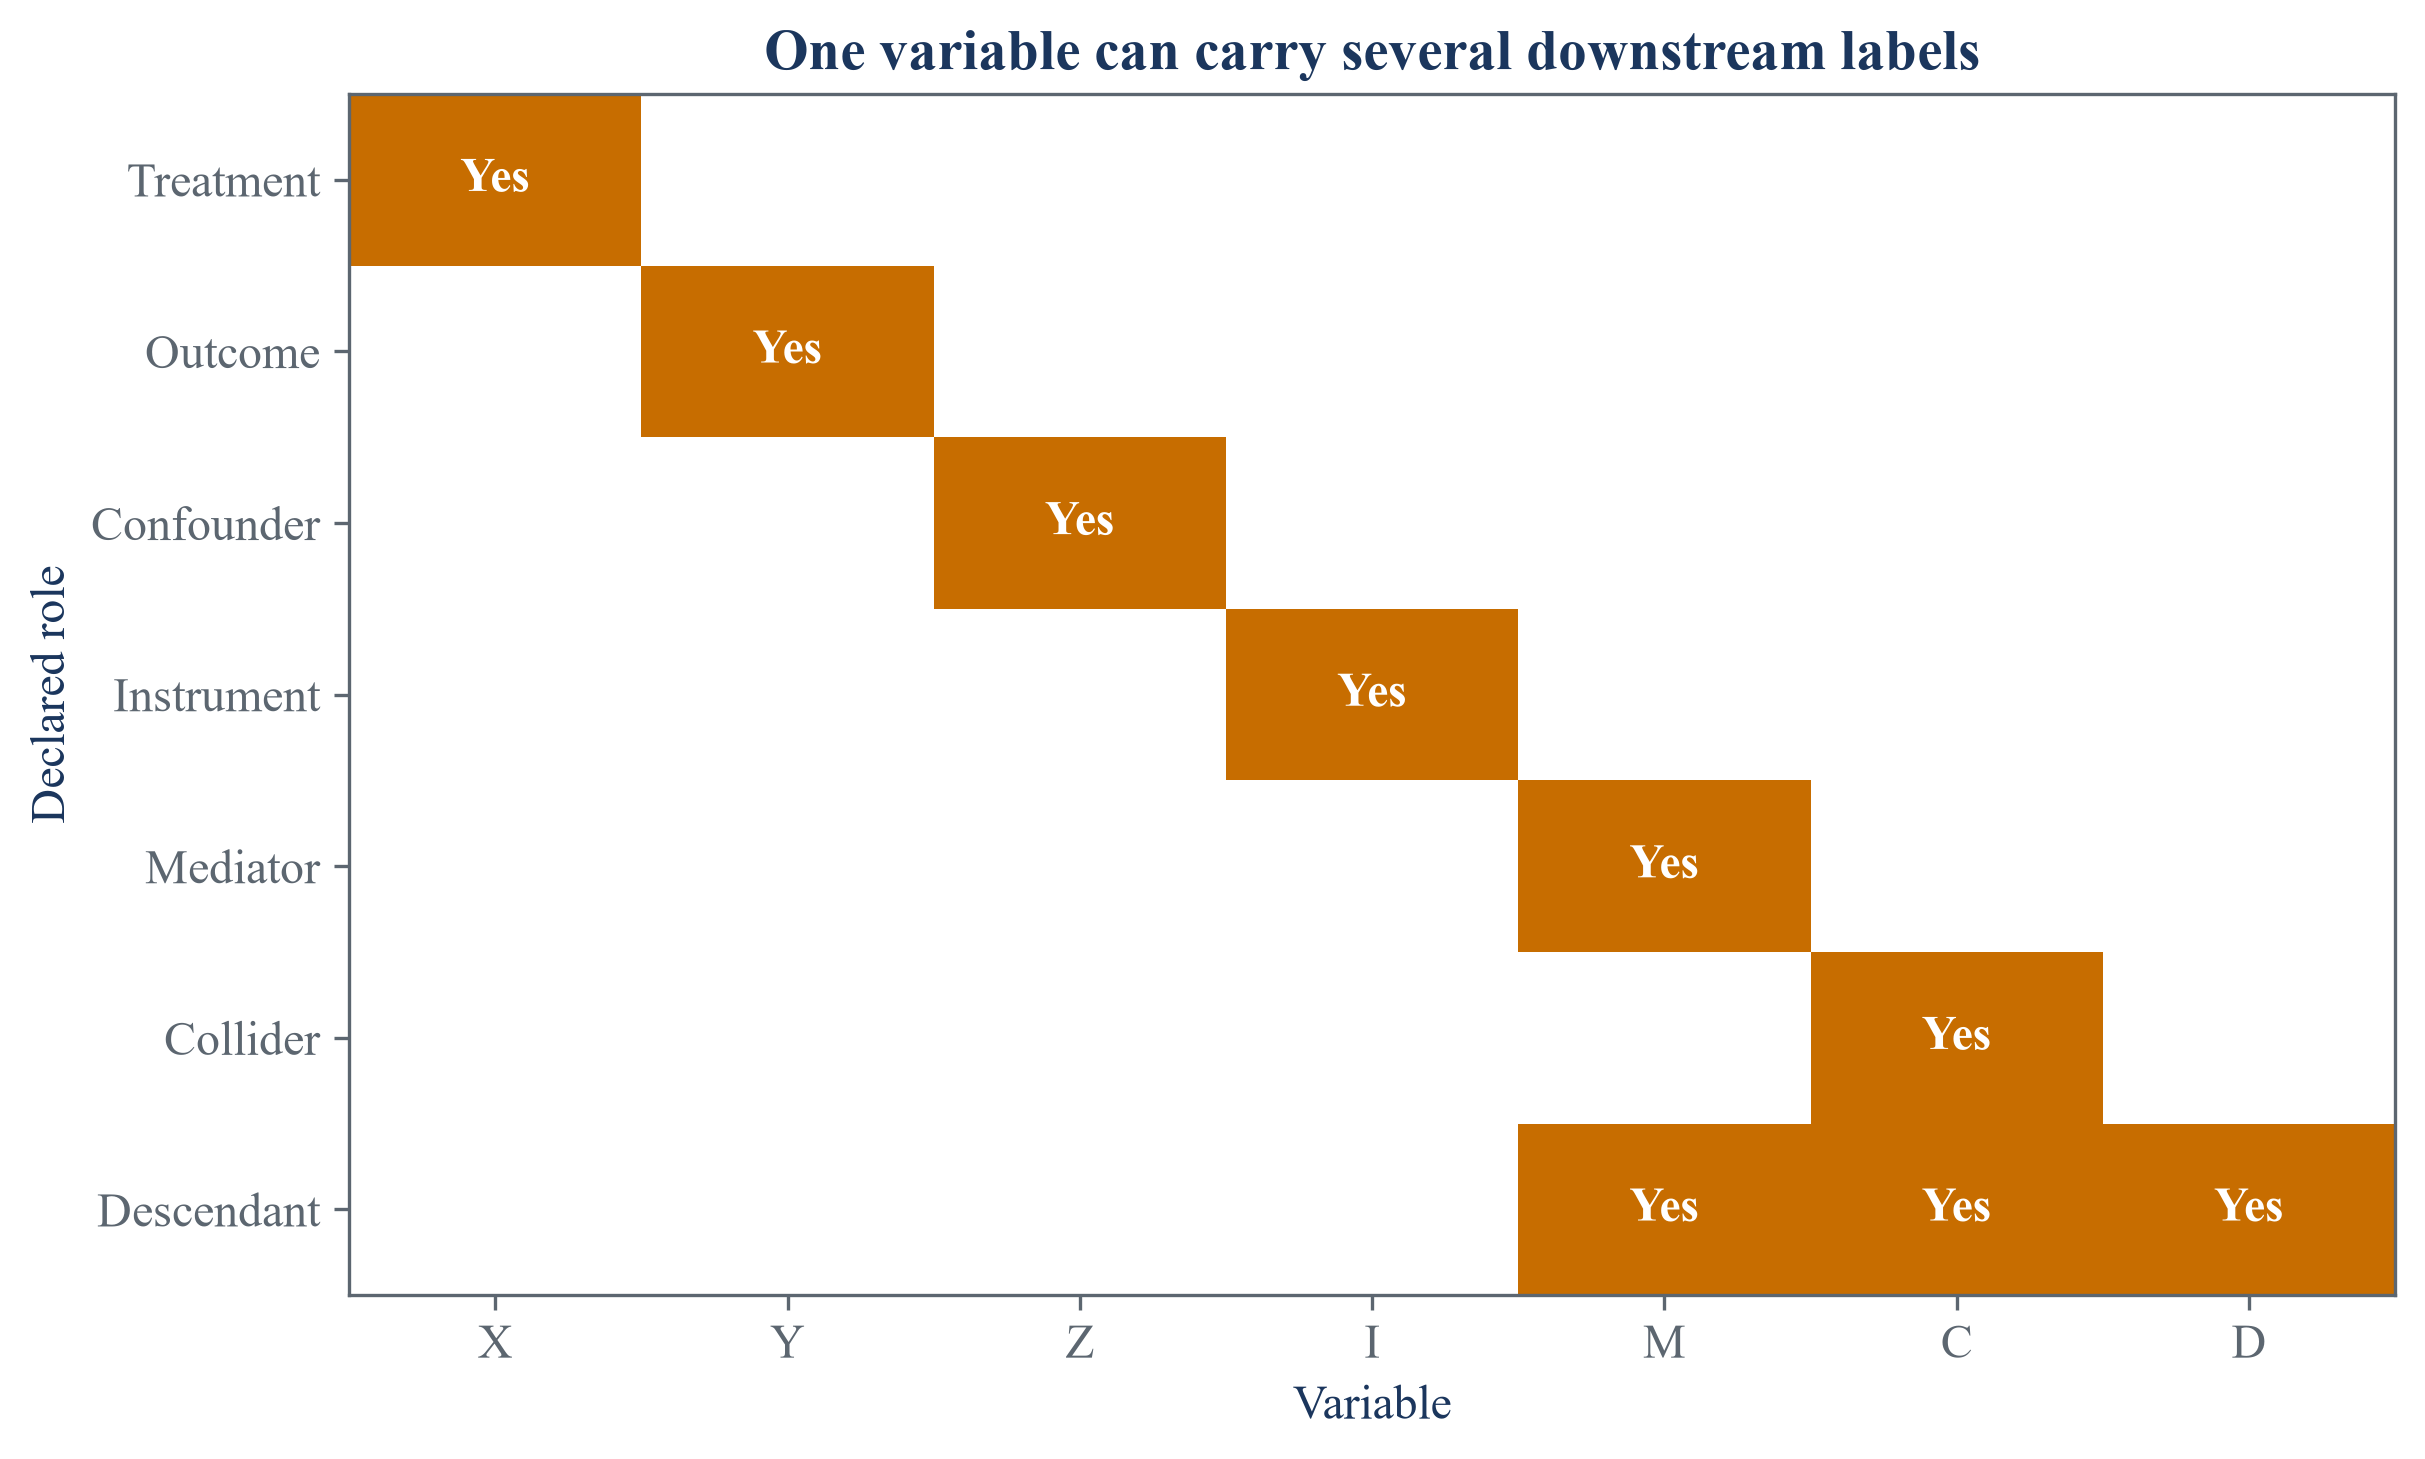

In [6]:
adjustment = report.causal_adjustment_set
role_rows = []
role_groups = [("Treatment", (adjustment.treatment,)), ("Outcome", (adjustment.outcome,)), ("Confounder", adjustment.confounders), ("Mediator", adjustment.mediators), ("Collider", adjustment.colliders), ("Descendant", adjustment.descendants), ("Instrument", adjustment.instruments), ("Selected control", adjustment.selected_adjustment_set)]
for role, values in role_groups:
    for value in values:
        role_rows.append({"Variable": value, "Graph role": role, "Used as ordinary control": value in adjustment.selected_adjustment_set})
role_table = pd.DataFrame(role_rows).drop_duplicates()
save_table(role_table, "protocol_graph_roles", "Declared graph roles and ordinary-control use.", "tab:chapter28-graph-roles")
display(role_table)

identification_table = pd.DataFrame([{"Item": "Identification method", "Value": human_label(adjustment.method_label)}, {"Item": "Identified", "Value": "Yes" if adjustment.identified else "No"}, {"Item": "Admissible sets", "Value": "; ".join(", ".join(group) for group in adjustment.admissible_adjustment_sets)}, {"Item": "Selected set", "Value": ", ".join(adjustment.selected_adjustment_set)}, {"Item": "Open back-door paths", "Value": len(adjustment.open_backdoor_paths)}, {"Item": "Control reason", "Value": adjustment.control_justifications[0][1]}])
save_table(identification_table, "protocol_adjustment_evidence", "Identification evidence for the supplied back-door adjustment.", "tab:chapter28-adjustment-evidence")
display(identification_table)

variables = ["X", "Y", "Z", "I", "M", "C", "D"]
roles = ["Treatment", "Outcome", "Confounder", "Instrument", "Mediator", "Collider", "Descendant"]
role_matrix = np.zeros((len(roles), len(variables)))
declared = {"Treatment": {"X"}, "Outcome": {"Y"}, "Confounder": {"Z"}, "Instrument": {"I"}, "Mediator": {"M"}, "Collider": {"C"}, "Descendant": set(adjustment.descendants)}
for row, role in enumerate(roles):
    for column, variable in enumerate(variables):
        role_matrix[row, column] = variable in declared[role]
figure, axis = plt.subplots(figsize=(8.8, 5.2))
axis.imshow(role_matrix, cmap=matplotlib.colors.ListedColormap([palette["axes"], palette["amber"]]), vmin=0, vmax=1, aspect="auto")
axis.set_xticks(range(len(variables)), variables)
axis.set_yticks(range(len(roles)), roles)
axis.set_xlabel("Variable")
axis.set_ylabel("Declared role")
axis.set_title("One variable can carry several downstream labels")
for row in range(role_matrix.shape[0]):
    for column in range(role_matrix.shape[1]):
        if role_matrix[row, column]:
            axis.text(column, row, "Yes", ha="center", va="center", color=palette["background"], fontweight="bold")
save_figure(figure, "protocol_graph_roles")

## Recording invalid graph declarations

,Case,Stage,Result,Message,Rejected
0,Ambiguous graph edge,Stage 2,Rejected,Stage 2: identification-relevant ambiguity mus...,True
1,Directed cycle,Stage 2,Rejected,Stage 2: the resolved graph must be acyclic,True
2,Selected variable absent from graph,Stage 2,Rejected,Stage 2: graph nodes must match the selected v...,True
3,Collider used as control,Stage 3,Rejected,Stage 3: ordinary controls cannot include desc...,True
4,Mediator used as control,Stage 3,Rejected,Stage 3: ordinary controls cannot include desc...,True
5,Descendant used as control,Stage 3,Rejected,Stage 3: ordinary controls cannot include desc...,True
6,Open back-door path,Stage 3,Rejected,Stage 3: no backdoor path may remain open,True


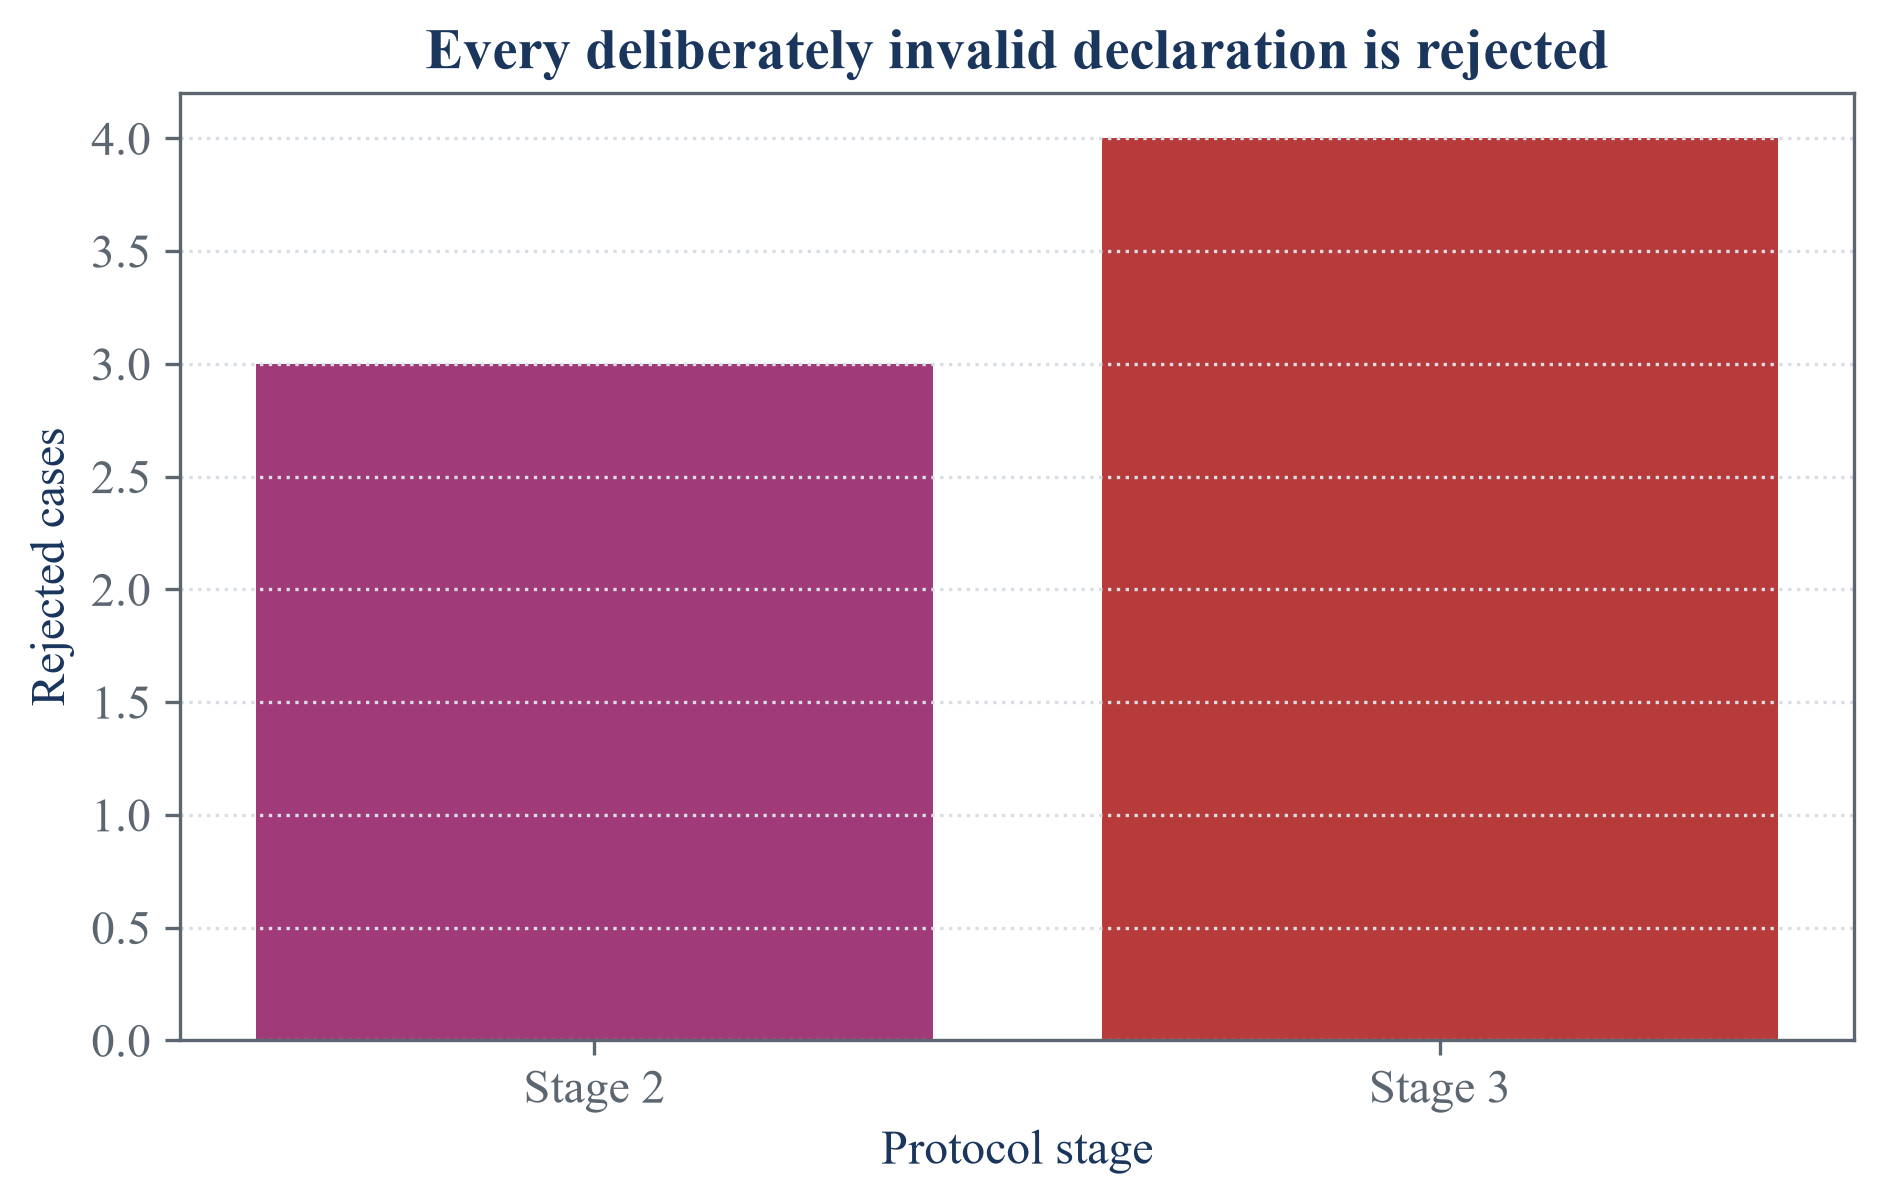

,Question,Evidence
0,Was overlap stated and handled?,"Event horizons, purged folds, and embargo"
1,Was selection repeated inside training?,Distinct refit records and recorded selection ...
2,Is the graph resolved and acyclic?,"Nodes, directed edges, no ambiguous edges, and..."
3,Is adjustment graph-valid?,"Admissible sets, role exclusions, reasons, and..."
4,Does a pass prove causal truth?,No. It proves only that the supplied record me...


In [7]:
invalid_rows = []
invalid_rows.append(contract_case("Ambiguous graph edge", "Stage 2", lambda: validate_causal_factor_protocol(replace(report, causal_discovery=replace(report.causal_discovery, ambiguous_edges=(("X", "Y"),))))))
invalid_rows.append(contract_case("Directed cycle", "Stage 2", lambda: validate_causal_factor_protocol(replace(report, causal_discovery=replace(report.causal_discovery, directed_edges=report.causal_discovery.directed_edges + (("Y", "X"),))))))
missing_nodes = tuple(value for value in report.causal_discovery.graph_nodes if value != "D")
missing_edges = tuple(edge for edge in report.causal_discovery.directed_edges if "D" not in edge)
invalid_rows.append(contract_case("Selected variable absent from graph", "Stage 2", lambda: validate_causal_factor_protocol(replace(report, causal_discovery=replace(report.causal_discovery, graph_nodes=missing_nodes, directed_edges=missing_edges)))))
for variable, role in [("C", "Collider used as control"), ("M", "Mediator used as control"), ("D", "Descendant used as control")]:
    changed = replace(report.causal_adjustment_set, admissible_adjustment_sets=(("Z", variable),), selected_adjustment_set=("Z", variable), control_justifications=(("Z", "Common cause."), (variable, "Invalid ordinary control.")))
    invalid_rows.append(contract_case(role, "Stage 3", lambda changed=changed: validate_causal_factor_protocol(replace(report, causal_adjustment_set=changed))))
invalid_rows.append(contract_case("Open back-door path", "Stage 3", lambda: validate_causal_factor_protocol(replace(report, causal_adjustment_set=replace(report.causal_adjustment_set, open_backdoor_paths=("X <- Z -> Y",))))))
invalid_table = pd.DataFrame(invalid_rows)
save_table(invalid_table, "protocol_stage23_rejections", "Graph and adjustment declarations rejected by the released checks.", "tab:chapter28-stage23-rejections")
display(invalid_table)

rejection_counts = invalid_table.groupby("Stage")["Rejected"].sum().reset_index(name="Rejected cases")
save_table(rejection_counts, "protocol_stage23_rejection_counts", "Rejected cases by protocol stage.", "tab:chapter28-stage23-rejection-counts")
figure, axis = plt.subplots(figsize=(7.2, 4.1))
axis.bar(rejection_counts["Stage"], rejection_counts["Rejected cases"], color=[palette["violet"], palette["rose"]])
axis.set_xlabel("Protocol stage")
axis.set_ylabel("Rejected cases")
axis.set_title("Every deliberately invalid declaration is rejected")
axis.grid(True, axis="y")
save_figure(figure, "protocol_stage23_rejections")

section_summary = pd.DataFrame([{"Question": "Was overlap stated and handled?", "Evidence": "Event horizons, purged folds, and embargo"}, {"Question": "Was selection repeated inside training?", "Evidence": "Distinct refit records and recorded selection refits"}, {"Question": "Is the graph resolved and acyclic?", "Evidence": "Nodes, directed edges, no ambiguous edges, and assumptions"}, {"Question": "Is adjustment graph-valid?", "Evidence": "Admissible sets, role exclusions, reasons, and closed back-door paths"}, {"Question": "Does a pass prove causal truth?", "Evidence": "No. It proves only that the supplied record meets the structural conditions"}])
save_table(section_summary, "protocol_section1_summary", "Questions answered by the first three protocol stages.", "tab:chapter28-section1-summary")
display(section_summary)

## Tests

In [8]:
assert report.stage_names == ("Variable Selection", "Causal Discovery", "Causal Adjustment Set", "Causal Explanatory and Predictive Power", "Causal Portfolio Construction", "Backtest", "Multiple Testing Adjustments")
assert report.source_oracle == "PROTOCOL-01"
assert len(stage_table) == 7
assert overlap[0, 1] == 1 and overlap[0, 2] == 0
assert all(set(fold.train_ids).isdisjoint(fold.test_ids) for fold in validation.folds)
assert embargo_table.loc[embargo_table["Embargo"] == 0.0, "Accepted"].iloc[0] == False
assert embargo_table.loc[embargo_table["Embargo"] == 1.0, "Accepted"].iloc[0] == True
assert set(report.variable_selection.selected_variables).issubset(set(report.causal_discovery.graph_nodes))
assert report.causal_adjustment_set.selected_adjustment_set == ("Z",)
assert invalid_table["Rejected"].all()
assert rejection_counts["Rejected cases"].sum() == len(invalid_table)
for stem in ["protocol_stage_flow", "protocol_overlap_heatmap", "protocol_fold_membership", "protocol_embargo_sweep", "protocol_selection_refits", "protocol_causal_graph", "protocol_graph_roles", "protocol_stage23_rejections"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["protocol_stage_order", "protocol_provenance", "protocol_event_horizons", "protocol_overlap_matrix", "protocol_fold_membership", "protocol_embargo_sweep", "protocol_selection_methods", "protocol_selection_refits", "protocol_graph_edges", "protocol_graph_assumptions", "protocol_graph_roles", "protocol_adjustment_evidence", "protocol_stage23_rejections", "protocol_stage23_rejection_counts", "protocol_section1_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()